# Minor Project — Predictive Classification using Random Forest Ensembles

**Course:** AIML Minor Project  
**Dataset:** Telco Customer Churn (Kaggle)  
**Target Variable:** Churn (Yes / No)  
**Algorithm:** RandomForestClassifier (scikit-learn)

---

### Project Pipeline
| Phase | Description |
|-------|-------------|
| **Phase I** | Exploratory Data Analysis (EDA)
| **Phase II** | Data Preprocessing
| **Phase III** | Model Development & Hyperparameter Tuning
| **Phase IV** | Evaluation Metrics & Visualizations
| **Phase V** | Export Cleaned Dataset & Conclusion

## Environment Setup — Install Required Libraries

In [ ]:
# Install imbalanced-learn for SMOTE which handles class imbalance
!pip install imbalanced-learn --quiet


##  Import Libraries

In [ ]:
# ── Standard Libraries ──────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualization ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted')

# ── Preprocessing ────────────────────────────────────────────────────────────
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV

# ── Class Imbalance ──────────────────────────────────────────────────────────
from imblearn.over_sampling import SMOTE

# ── Model ────────────────────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier

# ── Evaluation Metrics ───────────────────────────────────────────────────────
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score
)

print("libraries imported successfully")

libraries imported successfully


## Load Dataset

 **Instructions:** Upload the file WA_Fn-UseC_-Telco-Customer-Churn.csv when the upload dialog appears.

In [ ]:
# Load Dataset
FILE_PATH = '/content/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df_raw = pd.read_csv(FILE_PATH)
df = df_raw.copy()
print(f"Dataset loaded!  Shape: {df.shape}")

Dataset loaded!  Shape: (7043, 21)


# PHASE I — Exploratory Data Analysis (EDA)

**Goal:** Understand data structure, feature distributions, class balance, and inter-variable relationships.

### 1.1 — Dataset Overview

In [ ]:
# First 5 rows
print("First 5 rows of the raw dataset:")
df_raw.head()

First 5 rows of the raw dataset:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
# Data types and non-null counts
print("Dataset Info:")
df_raw.info()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-n

In [ ]:
# Statistical summary of numeric columns
print("Statistical Summary (Numeric Columns):")
df_raw.describe().round(2)

Statistical Summary (Numeric Columns):


,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


### 1.2 — Missing Values & Duplicates

In [ ]:
# Missing values
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print("Missing Values per Column:")
print(missing_df[missing_df['Missing Count'] > 0] if missing_df['Missing Count'].sum() > 0 else "No missing values found.")

print(f"\nDuplicate rows: {df_raw.duplicated().sum()}")

Missing Values per Column:
No missing values found.

Duplicate rows: 0


### 1.3 — Target Variable Distribution (Class Imbalance Check)

Churn Class Distribution:
   No   : 5,174 samples (73.5%)
   Yes  : 1,869 samples (26.5%)


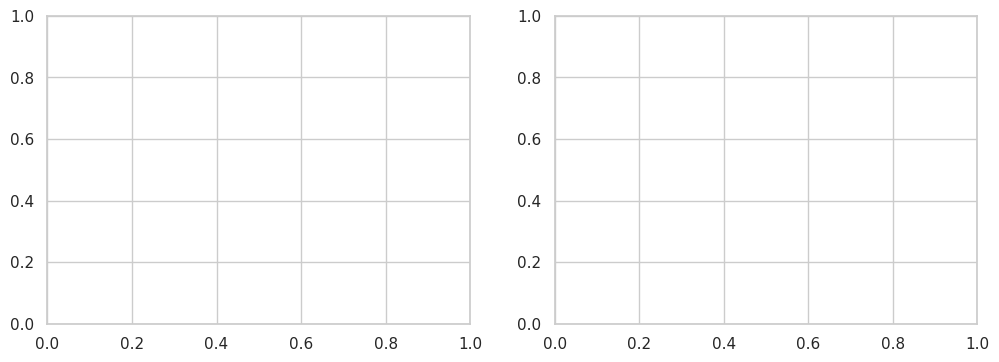

In [ ]:
# Class distribution
churn_counts = df_raw['Churn'].value_counts()
churn_pct    = df_raw['Churn'].value_counts(normalize=True) * 100

print("Churn Class Distribution:")
for label in churn_counts.index:
    print(f"   {label:5s}: {churn_counts[label]:,} samples ({churn_pct[label]:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plt.show()

In [ ]:
# Count plot
sns.countplot(x='Churn', data=df_raw, palette=['#2196F3', '#F44336'], ax=axes[0])
axes[0].set_title('Churn Count', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Churn', fontsize=11)
axes[0].set_ylabel('Number of Customers', fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom', fontweight='bold')

plt.show()

/tmp/ipykernel_830/1620781238.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Churn', data=df_raw, palette=['#2196F3', '#F44336'], ax=axes[0])


In [ ]:
# Pie chart
axes[1].pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%',
            colors=['#2196F3', '#F44336'], startangle=90,
            wedgeprops=dict(edgecolor='white', linewidth=2))
axes[1].set_title('Churn Proportion', fontsize=13, fontweight='bold')

plt.suptitle('Target Variable — Churn Distribution', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('churn_distribution.png', bbox_inches='tight', dpi=150)
plt.show()



print("\nClass Imbalance Detected: ~26.5% Churn vs ~73.5% No-Churn.")
print("-→ SMOTE will be applied after train-test split to balance the training set.")

<Figure size 640x480 with 0 Axes>


Class Imbalance Detected: ~26.5% Churn vs ~73.5% No-Churn.
-→ SMOTE will be applied after train-test split to balance the training set.


### 1.4 — Categorical Feature Distributions

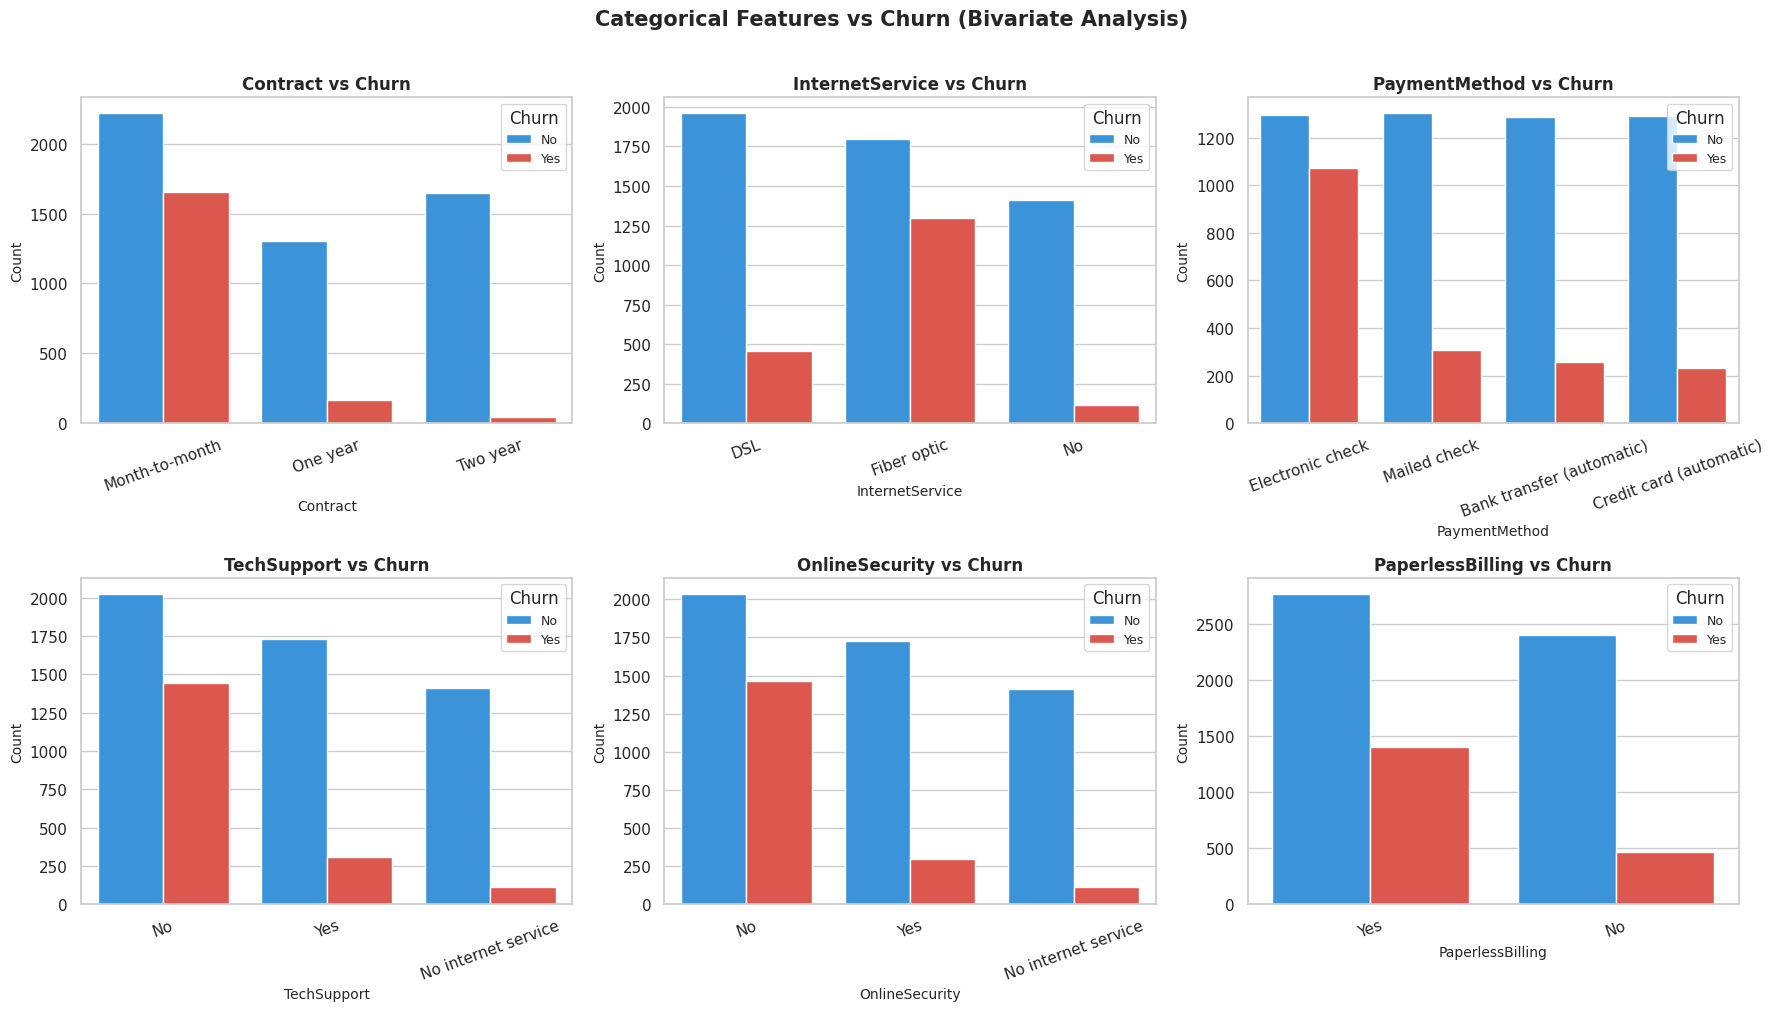

In [ ]:
# Bivariate plots: key categorical features vs Churn
cat_features = ['Contract', 'InternetService', 'PaymentMethod',
                'TechSupport', 'OnlineSecurity', 'PaperlessBilling']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    sns.countplot(x=col, hue='Churn', data=df_raw, palette=['#2196F3', '#F44336'], ax=axes[i])
    axes[i].set_title(f'{col} vs Churn', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Count', fontsize=10)
    axes[i].tick_params(axis='x', rotation=20)
    axes[i].legend(title='Churn', fontsize=9)

plt.suptitle('Categorical Features vs Churn (Bivariate Analysis)',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('categorical_vs_churn.png', bbox_inches='tight', dpi=150)
plt.show()

### 1.5 — Numeric Feature Distributions & Outlier Check

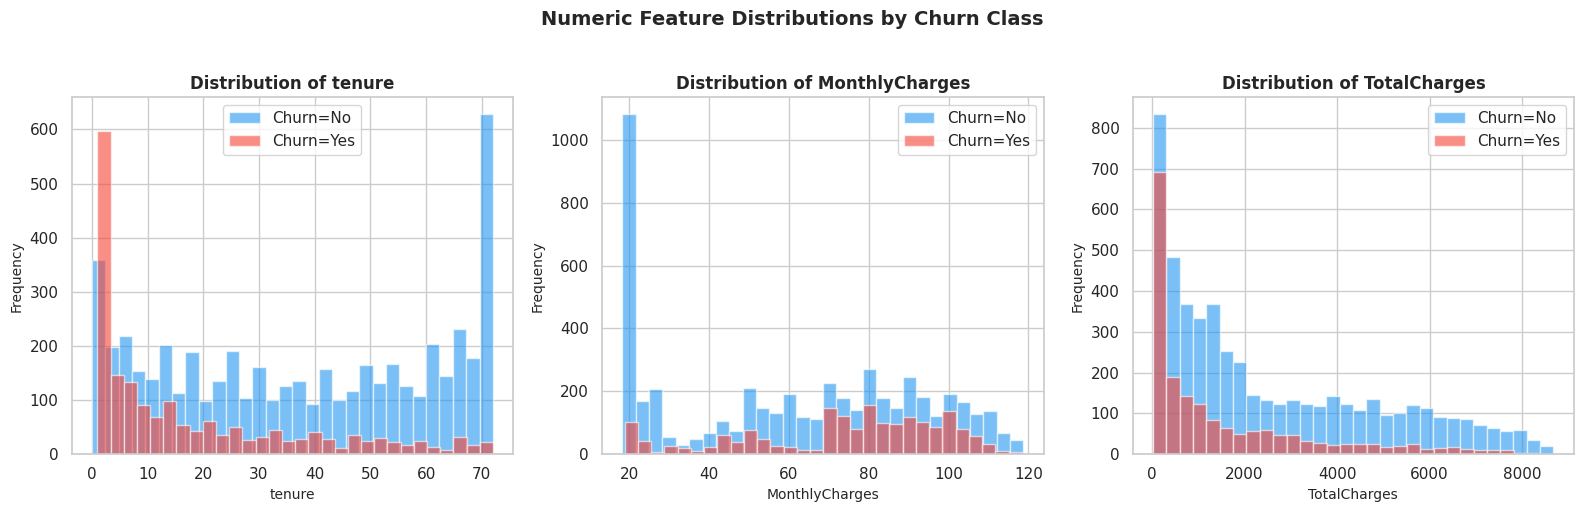

In [ ]:
# Histogram + KDE for numeric features split by Churn
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, col in enumerate(num_features):
    # Convert TotalCharges to numeric (may have whitespace strings)
    series = pd.to_numeric(df_raw[col], errors='coerce')
    for churn_val, color in zip(['No', 'Yes'], ['#2196F3', '#F44336']):
        mask = df_raw['Churn'] == churn_val
        axes[i].hist(series[mask].dropna(), bins=30, alpha=0.6,
                     label=f'Churn={churn_val}', color=color, edgecolor='white')
    axes[i].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)
    axes[i].legend()

plt.suptitle('Numeric Feature Distributions by Churn Class',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('numeric_distributions.png', bbox_inches='tight', dpi=150)
plt.show()

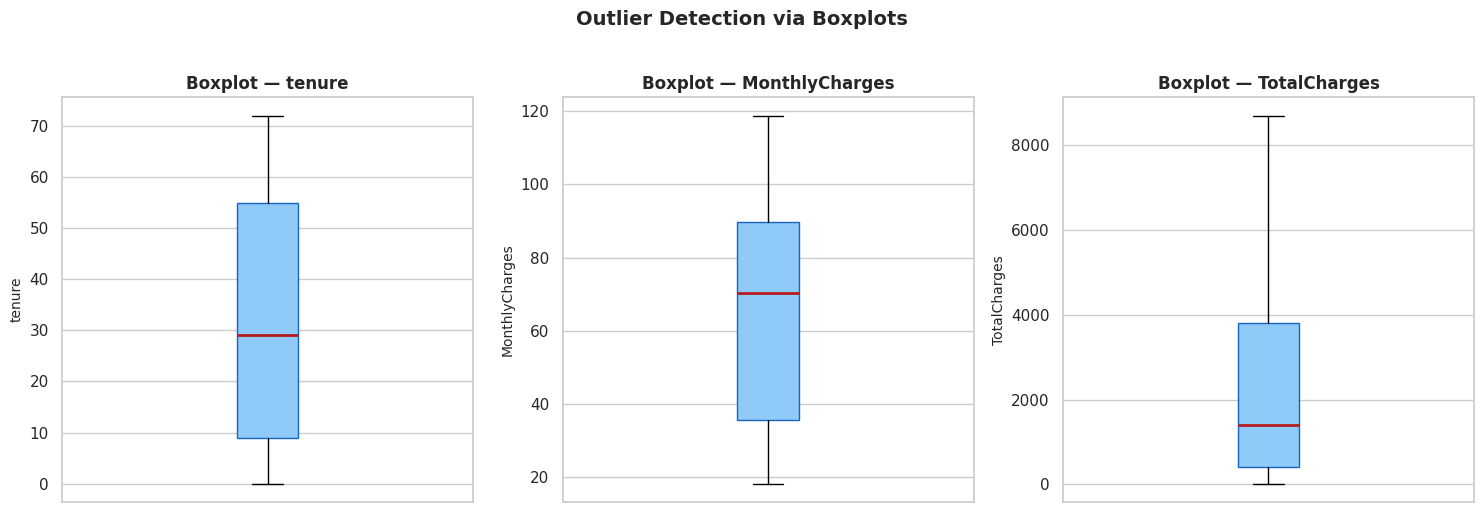

Outliers observed in TotalCharges and MonthlyCharges are valid customer behaviour — not errors.
-→ Random Forest is robust to outliers; no capping is required.


In [ ]:
# Boxplots for outlier detection
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(num_features):
    series = pd.to_numeric(df_raw[col], errors='coerce')
    axes[i].boxplot(series.dropna(), patch_artist=True,
                    boxprops=dict(facecolor='#90CAF9', color='#1565C0'),
                    medianprops=dict(color='#B71C1C', linewidth=2))
    axes[i].set_title(f'Boxplot — {col}', fontsize=12, fontweight='bold')
    axes[i].set_ylabel(col, fontsize=10)
    axes[i].set_xticks([])

plt.suptitle('Outlier Detection via Boxplots', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('boxplots_outliers.png', bbox_inches='tight', dpi=150)
plt.show()
print("Outliers observed in TotalCharges and MonthlyCharges are valid customer behaviour — not errors.")
print("-→ Random Forest is robust to outliers; no capping is required.")

# 🛠️ PHASE II — Data Preprocessing

Steps:
1. Drop irrelevant columns (customerID)
2. Fix data-type issues (TotalCharges)
3. Handle missing / null values
4. Label-encode all categorical columns
5. Train-Test split (80:20)
6. Apply SMOTE to training set only
7. Export cleaned dataset

In [ ]:
# Work on a copy to preserve the raw data
df = df_raw.copy()
print(f"Working copy created. Shape: {df.shape}")

Working copy created. Shape: (7043, 21)


### 2.1 — Drop Irrelevant Columns

In [ ]:
# 'customerID' is a unique identifier — carries no predictive signal
df.drop(columns=['customerID'], inplace=True)
print(f"Dropped 'customerID'. Remaining columns: {df.shape[1]}")

Dropped 'customerID'. Remaining columns: 20


### 2.2 — Fix Data Types & Handle Missing Values

In [ ]:
# TotalCharges is stored as object (some rows contain whitespace " " instead of NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(f"NaN count in 'TotalCharges' after coercion: {df['TotalCharges'].isna().sum()}")

# Fill NaN with column median (robust to outliers vs. mean)
median_tc = df['TotalCharges'].median()
df['TotalCharges'].fillna(median_tc, inplace=True)

print(f"Missing 'TotalCharges' imputed with median: {median_tc:.2f}")
print(f"Total NaN values remaining in dataset: {df.isnull().sum().sum()}")

NaN count in 'TotalCharges' after coercion: 11
Missing 'TotalCharges' imputed with median: 1397.47
Total NaN values remaining in dataset: 0


/tmp/ipykernel_830/1722113019.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(median_tc, inplace=True)


### 2.3 — Label Encoding for Categorical Features

 **Why Label Encoding?**  
 Random Forest is a tree-based algorithm. It splits on feature values using thresholds, so it does not require one-hot encoding.

In [ ]:
le = LabelEncoder()
categorical_cols = df.select_dtypes(include='object').columns.tolist()

print(f"Categorical columns to encode ({len(categorical_cols)}):")
print(categorical_cols)

label_mappings = {}  # Store mappings for reference
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])
    label_mappings[col] = dict(zip(le.classes_, le.transform(le.classes_)))

print("\nLabel encoding complete.")
print("\nEncoding mappings:")
for col, mapping in label_mappings.items():
    print(f"   {col}: {mapping}")

Categorical columns to encode (16):
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']

Label encoding complete.

Encoding mappings:
   gender: {'Female': np.int64(0), 'Male': np.int64(1)}
   Partner: {'No': np.int64(0), 'Yes': np.int64(1)}
   Dependents: {'No': np.int64(0), 'Yes': np.int64(1)}
   PhoneService: {'No': np.int64(0), 'Yes': np.int64(1)}
   MultipleLines: {'No': np.int64(0), 'No phone service': np.int64(1), 'Yes': np.int64(2)}
   InternetService: {'DSL': np.int64(0), 'Fiber optic': np.int64(1), 'No': np.int64(2)}
   OnlineSecurity: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
   OnlineBackup: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
   DeviceProtection: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes'

### 2.4 — Export Cleaned Dataset

In [ ]:
# Save the fully preprocessed (cleaned + encoded) dataset
cleaned_filename = 'Telco_Churn_Cleaned.csv'
df.to_csv(cleaned_filename, index=False)

print(f"Cleaned dataset saved as '{cleaned_filename}'")
print(f"Shape : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"\nPreview of cleaned dataset:")
df.head()

Cleaned dataset saved as 'Telco_Churn_Cleaned.csv'
Shape : 7,043 rows × 20 columns

Preview of cleaned dataset:


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1
3,1,0,0,0,45,0,1,0,2,0,2,2,0,0,1,0,0,42.30,1840.75,0
4,0,0,0,0,2,1,0,1,0,0,0,0,0,0,0,1,2,70.70,151.65,1


In [ ]:
# Download cleaned file to your local machine
from google.colab import files
files.download(cleaned_filename)
print(f" '{cleaned_filename}' download started.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 'Telco_Churn_Cleaned.csv' download started.


### 2.5 — Correlation Heatmap (Post-Encoding)

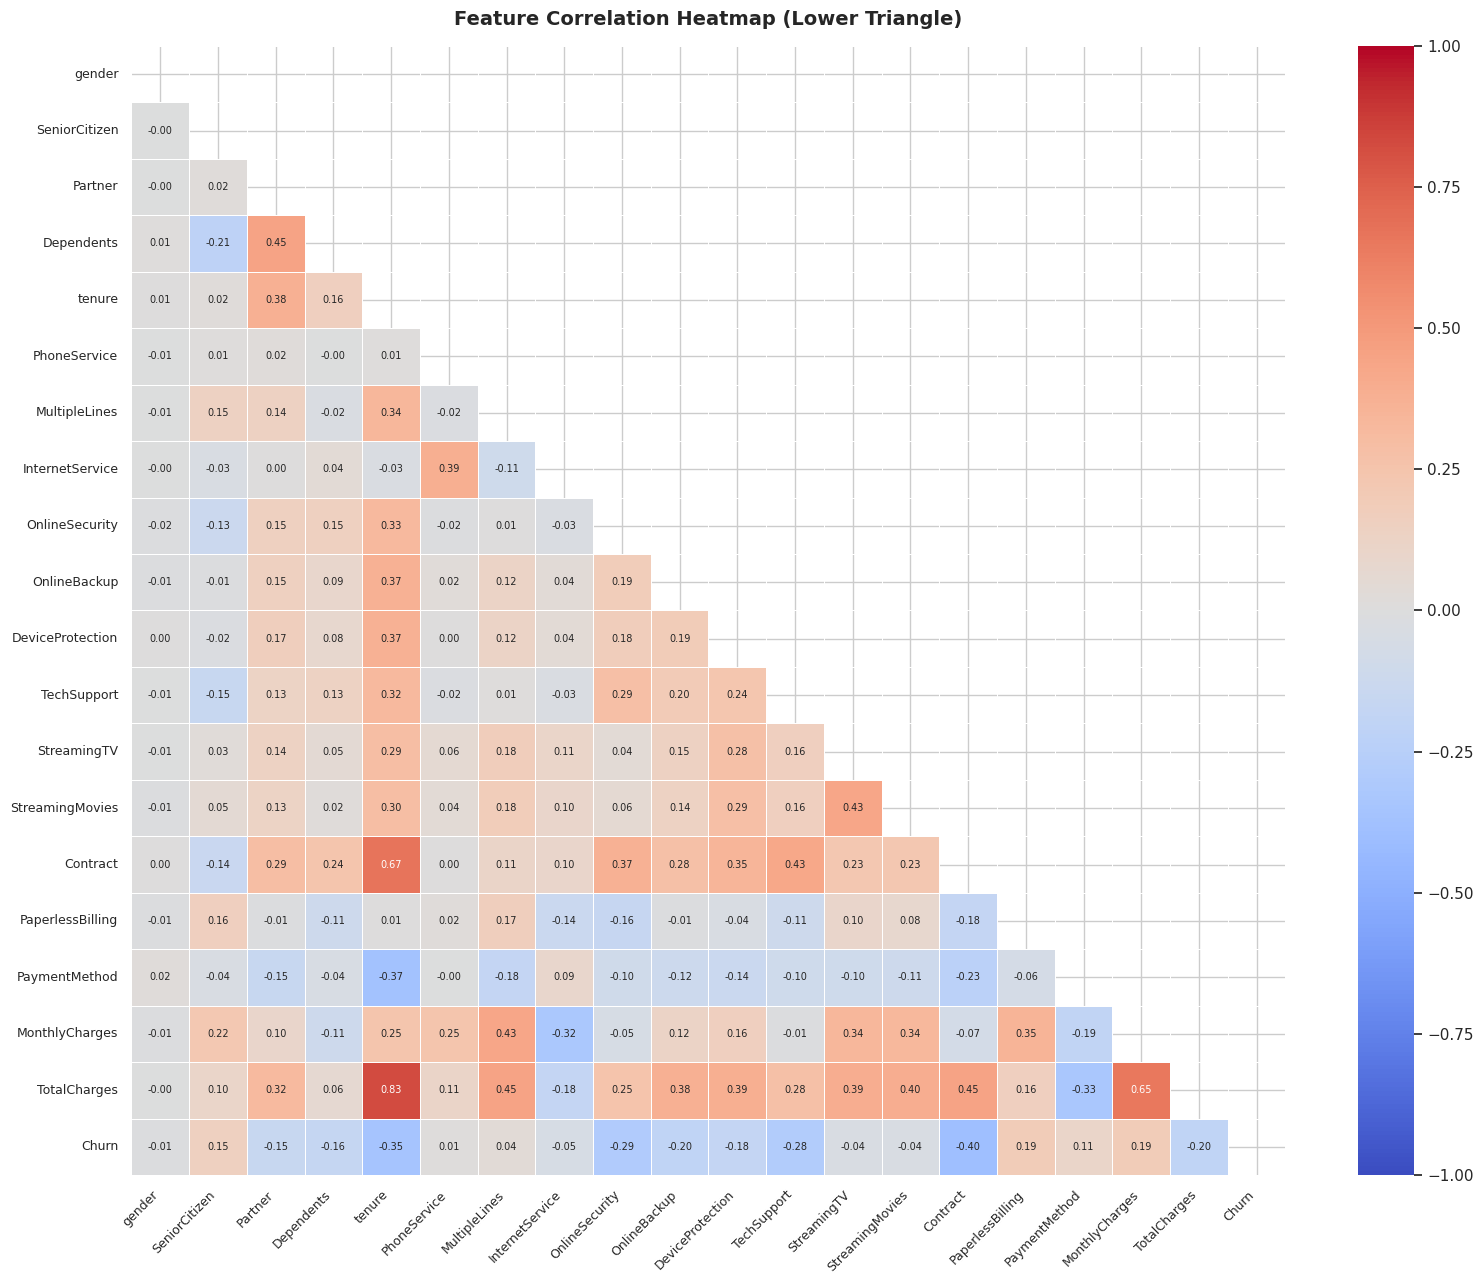

In [ ]:
# Full correlation matrix with target highlighted
corr = df.corr()

plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))  # upper triangle mask
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, linecolor='white',
            vmin=-1, vmax=1, center=0,
            annot_kws={'size': 7})
plt.title('Feature Correlation Heatmap (Lower Triangle)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', bbox_inches='tight', dpi=150)
plt.show()

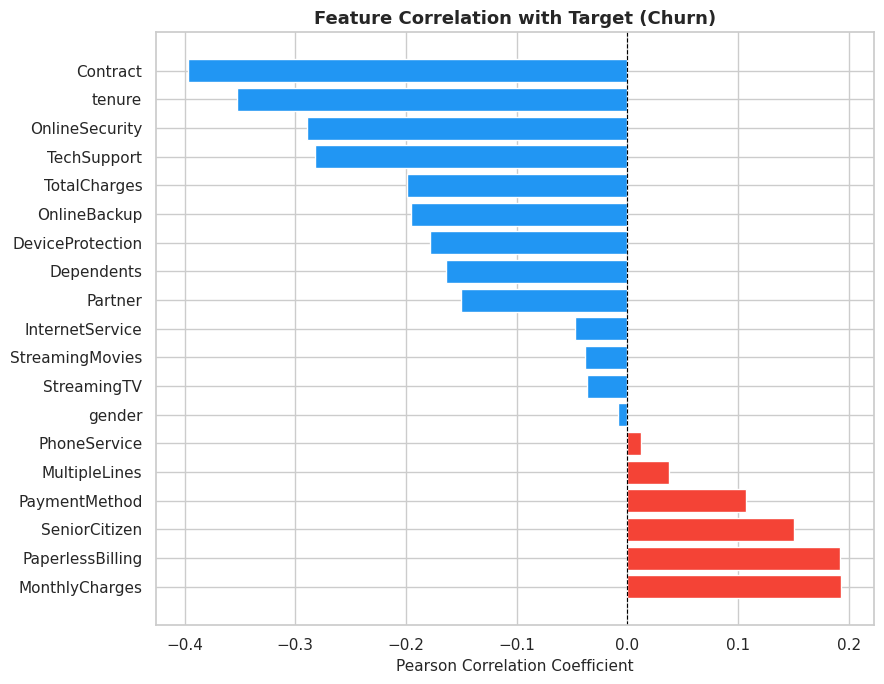


Top 5 features most positively correlated with Churn:
MonthlyCharges      0.193
PaperlessBilling    0.192
SeniorCitizen       0.151
PaymentMethod       0.107
MultipleLines       0.038

Top 5 features most negatively correlated with Churn:
TotalCharges     -0.199
TechSupport      -0.282
OnlineSecurity   -0.289
tenure           -0.352
Contract         -0.397


In [ ]:
# Correlation with target 'Churn' — sorted
target_corr = corr['Churn'].drop('Churn').sort_values(ascending=False)

plt.figure(figsize=(9, 7))
colors = ['#F44336' if v > 0 else '#2196F3' for v in target_corr.values]
bars = plt.barh(target_corr.index, target_corr.values, color=colors, edgecolor='white')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Feature Correlation with Target (Churn)', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient', fontsize=11)
plt.tight_layout()
plt.savefig('corr_with_target.png', bbox_inches='tight', dpi=150)
plt.show()

print("\nTop 5 features most positively correlated with Churn:")
print(target_corr.head().round(3).to_string())
print("\nTop 5 features most negatively correlated with Churn:")
print(target_corr.tail().round(3).to_string())

### 2.6 — Train-Test Split (80:20)

In [ ]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train-Test Split Complete:")
print(f"   Training set : {X_train.shape[0]:,} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"   Test set     : {X_test.shape[0]:,} samples ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"\n   Training class distribution:")
print(y_train.value_counts().to_string())
print(f"\n   stratify=y ensures class proportion is preserved in both splits.")

Train-Test Split Complete:
   Training set : 5,634 samples (80.0%)
   Test set     : 1,409 samples (20.0%)

   Training class distribution:
Churn
0    4139
1    1495

   stratify=y ensures class proportion is preserved in both splits.


### 2.7 — Handling Class Imbalance with SMOTE

 **Why SMOTE?**  
 The dataset has ~73.5% Non-Churn vs ~26.5% Churn — a notable imbalance.  
 SMOTE (Synthetic Minority Over-sampling Technique) creates synthetic samples for the minority class in the training set only.  
 **Important:** SMOTE is applied ONLY to the training set to prevent data leakage into the test set.

SMOTE Applied to Training Set:

   Before SMOTE:
     {0: 4139, 1: 1495}

   After SMOTE:
     {0: 4139, 1: 4139}

   Training samples after SMOTE : 8,278


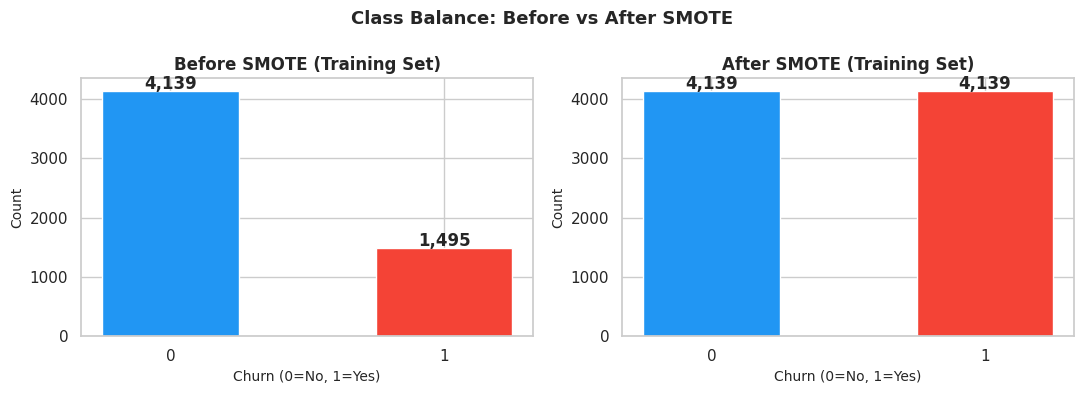

In [ ]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("SMOTE Applied to Training Set:")
print(f"\n   Before SMOTE:")
print(f"     {y_train.value_counts().to_dict()}")
print(f"\n   After SMOTE:")
print(f"     {pd.Series(y_train_smote).value_counts().to_dict()}")
print(f"\n   Training samples after SMOTE : {len(X_train_smote):,}")

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, counts, title in zip(
    axes,
    [y_train.value_counts(), pd.Series(y_train_smote).value_counts()],
    ['Before SMOTE (Training Set)', 'After SMOTE (Training Set)']
):
    ax.bar(counts.index.astype(str), counts.values, color=['#2196F3', '#F44336'], edgecolor='white', width=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Churn (0=No, 1=Yes)', fontsize=10)
    ax.set_ylabel('Count', fontsize=10)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 30, f'{v:,}', ha='center', fontweight='bold')

plt.suptitle('Class Balance: Before vs After SMOTE', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('smote_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

#PHASE III — Model Development

## 3.1 — Baseline Random Forest (Default Parameters)

In [ ]:
# Baseline model to understand starting performance before tuning
baseline_rf = RandomForestClassifier(n_estimators=100, random_state=42)
baseline_rf.fit(X_train_smote, y_train_smote)

y_pred_baseline = baseline_rf.predict(X_test)

print(" Baseline Random Forest — Test Set Performance:")
print(f"   Accuracy  : {accuracy_score(y_test, y_pred_baseline):.4f}")
print(f"   Precision : {precision_score(y_test, y_pred_baseline):.4f}")
print(f"   Recall    : {recall_score(y_test, y_pred_baseline):.4f}")
print(f"   F1-Score  : {f1_score(y_test, y_pred_baseline):.4f}")
print(f"   ROC-AUC   : {roc_auc_score(y_test, baseline_rf.predict_proba(X_test)[:, 1]):.4f}")

 Baseline Random Forest — Test Set Performance:
   Accuracy  : 0.7779
   Precision : 0.5801
   Recall    : 0.5909
   F1-Score  : 0.5854
   ROC-AUC   : 0.8217


## 3.2 — Hyperparameter Tuning with GridSearchCV

 **Hyperparameter Justification:**
 - **n_estimators**: More trees → more stable predictions
 - **max_depth**: Controls overfitting. None = grow full trees; shallower trees generalise better.
 - **min_samples_split** & **min_samples_leaf**: Minimum samples required at a node before splitting — regularises the tree.
 - **Scoring = F1**: Chosen because the dataset is imbalanced. F1 balances precision and recall better than accuracy.
 - **cv=5**: 5-fold cross-validation ensures robust, less-biased hyperparameter selection.



In [ ]:
param_grid = {
    'n_estimators'    : [100, 200, 300],
    'max_depth'       : [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf' : [1, 2, 4]
}

print("Starting GridSearchCV...")
print(f"   Total combinations to evaluate: "
      f"{len(param_grid['n_estimators']) * len(param_grid['max_depth']) * len(param_grid['min_samples_split']) * len(param_grid['min_samples_leaf'])} × 5-fold")

grid_search = GridSearchCV(
    estimator  = RandomForestClassifier(random_state=42),
    param_grid = param_grid,
    cv         = 5,
    scoring    = 'f1',
    n_jobs     = -1,
    verbose    = 1
)

grid_search.fit(X_train_smote, y_train_smote)

print("\nGridSearchCV Complete!")
print(f"   Best F1 Score (CV): {grid_search.best_score_:.4f}")
print(f"   Best Hyperparameters:")
for k, v in grid_search.best_params_.items():
    print(f"     {k}: {v}")

Starting GridSearchCV...
   Total combinations to evaluate: 81 × 5-fold
Fitting 5 folds for each of 81 candidates, totalling 405 fits

GridSearchCV Complete!
   Best F1 Score (CV): 0.8329
   Best Hyperparameters:
     max_depth: 20
     min_samples_leaf: 1
     min_samples_split: 2
     n_estimators: 300


## 3.3 — Best Model Predictions

In [ ]:
best_model = grid_search.best_estimator_

# Predictions
y_pred_train = best_model.predict(X_train_smote)
y_pred_test  = best_model.predict(X_test)
y_prob_test  = best_model.predict_proba(X_test)[:, 1]  # Probability for ROC-AUC

print("Best Model — Train vs Test Accuracy:")
print(f"   Train Accuracy : {accuracy_score(y_train_smote, y_pred_train):.4f}")
print(f"   Test Accuracy  : {accuracy_score(y_test, y_pred_test):.4f}")
print()
print("Detailed Classification Report (Test Set):")
print(classification_report(y_test, y_pred_test, target_names=['No Churn (0)', 'Churn (1)']))

Best Model — Train vs Test Accuracy:
   Train Accuracy : 0.9965
   Test Accuracy  : 0.7835

Detailed Classification Report (Test Set):
              precision    recall  f1-score   support

No Churn (0)       0.86      0.84      0.85      1035
   Churn (1)       0.59      0.62      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.73      1409
weighted avg       0.79      0.78      0.79      1409



#PHASE IV — Evaluation Metrics & Visualizations

## 4.1 — Confusion Matrix

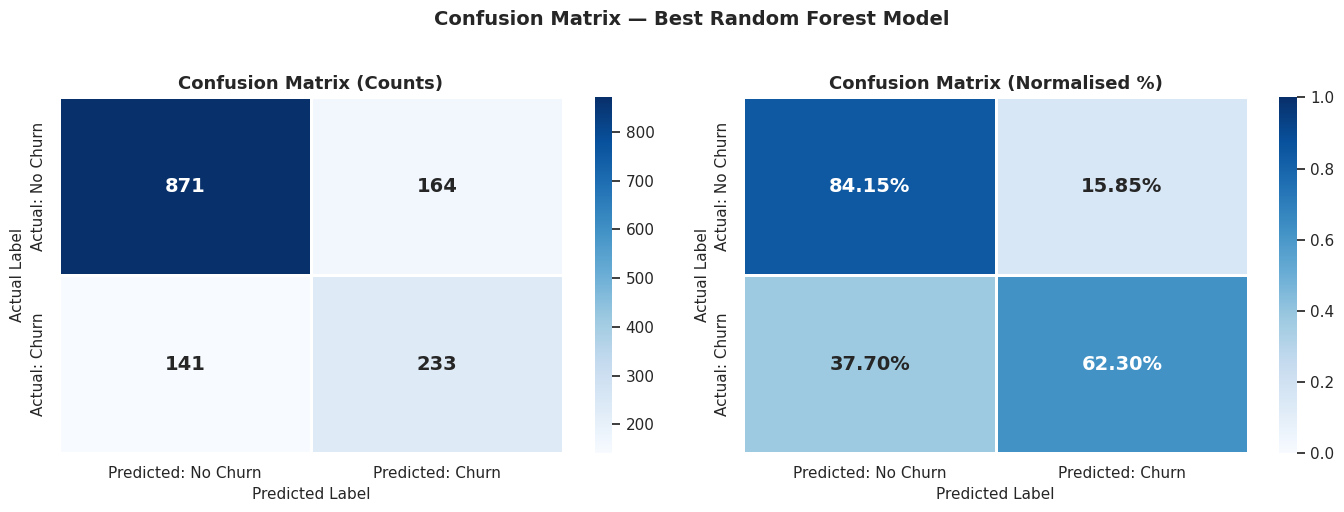


Confusion Matrix Breakdown:
   True Negatives  (TN) — Correctly predicted No Churn : 871
   False Positives (FP) — Predicted Churn, Actually No : 164
   False Negatives (FN) — Predicted No Churn, Actually : 141
   True Positives  (TP) — Correctly predicted Churn    : 233


In [ ]:
cm = confusion_matrix(y_test, y_pred_test)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap — raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted: No Churn', 'Predicted: Churn'],
            yticklabels=['Actual: No Churn', 'Actual: Churn'],
            linewidths=1, linecolor='white', ax=axes[0],
            annot_kws={'size': 14, 'fontweight': 'bold'})
axes[0].set_title('Confusion Matrix (Counts)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Actual Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)

# Heatmap — normalised %
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Predicted: No Churn', 'Predicted: Churn'],
            yticklabels=['Actual: No Churn', 'Actual: Churn'],
            linewidths=1, linecolor='white', ax=axes[1],
            vmin=0, vmax=1,
            annot_kws={'size': 14, 'fontweight': 'bold'})
axes[1].set_title('Confusion Matrix (Normalised %)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Actual Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)

plt.suptitle('Confusion Matrix — Best Random Forest Model',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrix.png', bbox_inches='tight', dpi=150)
plt.show()

print(f"\nConfusion Matrix Breakdown:")
print(f"   True Negatives  (TN) — Correctly predicted No Churn : {tn:,}")
print(f"   False Positives (FP) — Predicted Churn, Actually No : {fp:,}")
print(f"   False Negatives (FN) — Predicted No Churn, Actually : {fn:,}")
print(f"   True Positives  (TP) — Correctly predicted Churn    : {tp:,}")

## 4.2 — Precision, Recall & F1-Score

 **Trade-off Discussion:**  
 - **Precision** measures how many of our "Churn" predictions are actually correct. High precision = fewer false alarms.  
 - **Recall** measures how many actual churners we caught. High recall = we miss fewer real churners.  
 - In a churn context, **missing a churner (low recall) is more costly** than a false alarm, so we prioritise recall.  
 - **F1-Score** is the harmonic mean of Precision and Recall — ideal for imbalanced datasets where neither metric alone tells the full story.

Final Metrics on Test Set (Churn = Positive Class):
   Accuracy  : 0.7835  (78.35%)
   Precision : 0.5869  (58.69%)
   Recall    : 0.6230  (62.30%)
   F1-Score  : 0.6044  (60.44%)


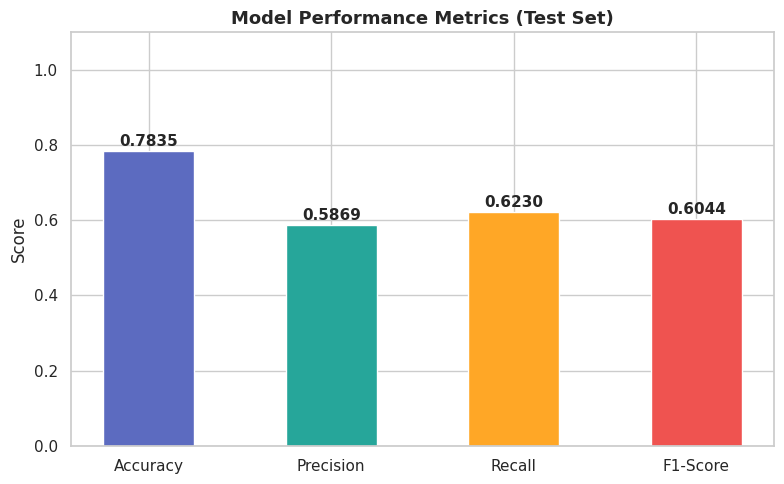

In [ ]:
precision = precision_score(y_test, y_pred_test)
recall    = recall_score(y_test, y_pred_test)
f1        = f1_score(y_test, y_pred_test)
accuracy  = accuracy_score(y_test, y_pred_test)

print("Final Metrics on Test Set (Churn = Positive Class):")
print(f"   Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"   Precision : {precision:.4f}  ({precision*100:.2f}%)")
print(f"   Recall    : {recall:.4f}  ({recall*100:.2f}%)")
print(f"   F1-Score  : {f1:.4f}  ({f1*100:.2f}%)")

# Bar chart of metrics
metrics = {'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1-Score': f1}
colors  = ['#5C6BC0', '#26A69A', '#FFA726', '#EF5350']

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics.keys(), metrics.values(), color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, metrics.values()):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=11)
plt.ylim(0, 1.1)
plt.ylabel('Score', fontsize=12)
plt.title('Model Performance Metrics (Test Set)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('performance_metrics.png', bbox_inches='tight', dpi=150)
plt.show()

## 4.3 — ROC-AUC Curve

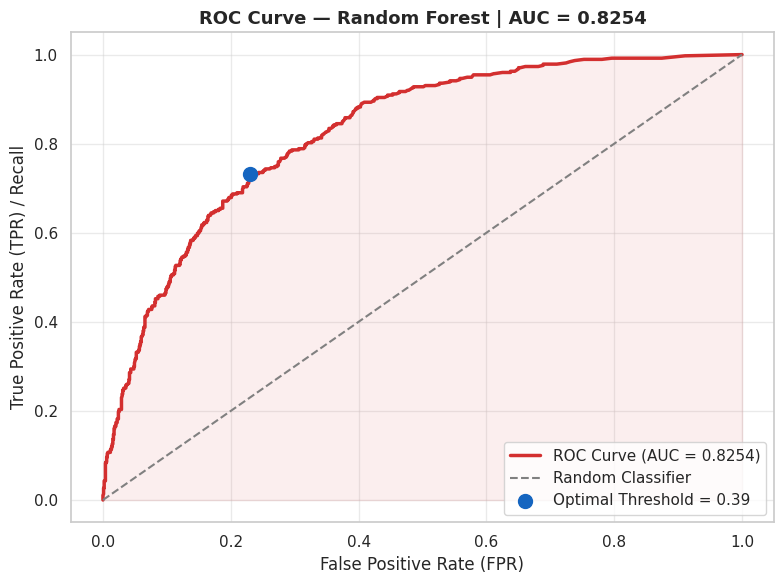


ROC-AUC Score : 0.8254
   Optimal Threshold (Youden's J) : 0.3863
   At optimal threshold → TPR: 0.7326 | FPR: 0.2300

Interpretation: An AUC closer to 1.0 means the model is excellent at discriminating
   between churners and non-churners across all classification thresholds.


In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_test)
auc_score = roc_auc_score(y_test, y_prob_test)

# Find optimal threshold (Youden's J statistic)
youden_j  = tpr - fpr
opt_idx   = np.argmax(youden_j)
opt_thresh = thresholds[opt_idx]

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#D32F2F', lw=2.5,
         label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Classifier')
plt.scatter(fpr[opt_idx], tpr[opt_idx], color='#1565C0', s=100, zorder=5,
            label=f'Optimal Threshold = {opt_thresh:.2f}')
plt.fill_between(fpr, tpr, alpha=0.08, color='#D32F2F')
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR) / Recall', fontsize=12)
plt.title(f'ROC Curve — Random Forest | AUC = {auc_score:.4f}', fontsize=13, fontweight='bold')
plt.legend(fontsize=11, loc='lower right')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('roc_auc_curve.png', bbox_inches='tight', dpi=150)
plt.show()

print(f"\nROC-AUC Score : {auc_score:.4f}")
print(f"   Optimal Threshold (Youden's J) : {opt_thresh:.4f}")
print(f"   At optimal threshold → TPR: {tpr[opt_idx]:.4f} | FPR: {fpr[opt_idx]:.4f}")
print("\nInterpretation: An AUC closer to 1.0 means the model is excellent at discriminating")
print("   between churners and non-churners across all classification thresholds.")

## 4.4 — Feature Importance

Feature Importances (Top 20):
         Feature  Importance
        Contract    0.139523
  MonthlyCharges    0.139456
    TotalCharges    0.135414
          tenure    0.119587
  OnlineSecurity    0.080577
     TechSupport    0.073978
   PaymentMethod    0.042469
    OnlineBackup    0.041899
      Dependents    0.032940
DeviceProtection    0.027644
 InternetService    0.026236
         Partner    0.025827
          gender    0.021507
   MultipleLines    0.019682
PaperlessBilling    0.018262
 StreamingMovies    0.016993
     StreamingTV    0.016936
   SeniorCitizen    0.014081
    PhoneService    0.006988


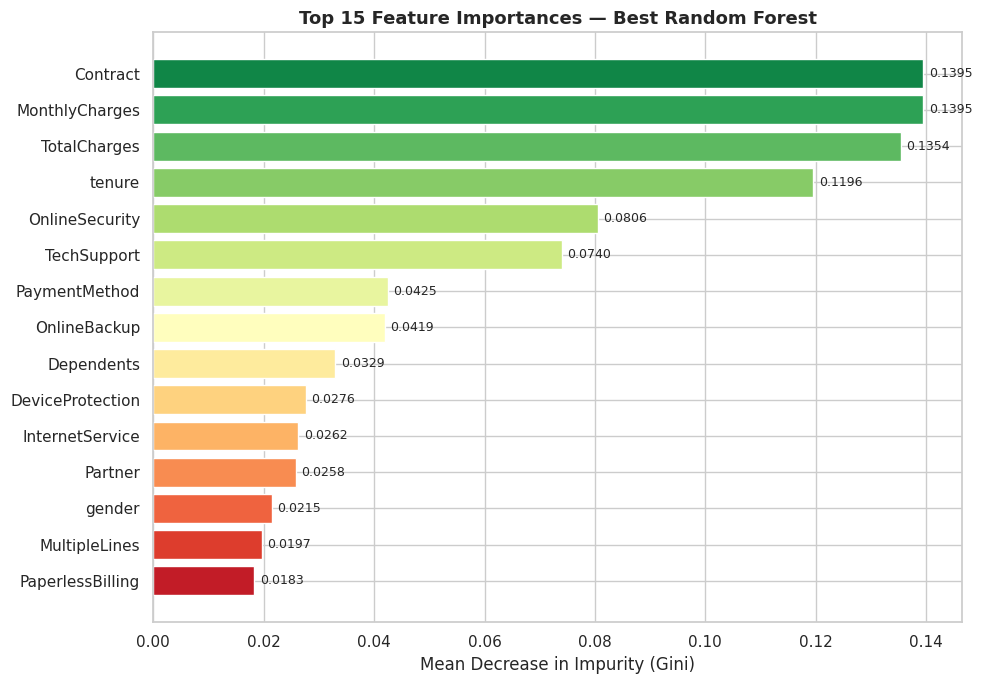


Most Important Feature: 'Contract' (Importance = 0.1395)


In [ ]:
importances = best_model.feature_importances_
feature_names = X.columns.tolist()

fi_df = pd.DataFrame({
    'Feature'   : feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print("Feature Importances (Top 20):")
print(fi_df.head(20).to_string(index=False))

# Bar chart
top_n = 15
fi_top = fi_df.head(top_n)

palette = sns.color_palette('RdYlGn_r', top_n)
plt.figure(figsize=(10, 7))
bars = plt.barh(fi_top['Feature'][::-1], fi_top['Importance'][::-1],
                color=palette[::-1], edgecolor='white')
for bar, val in zip(bars, fi_top['Importance'][::-1]):
    plt.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)
plt.xlabel('Mean Decrease in Impurity (Gini)', fontsize=12)
plt.title(f'Top {top_n} Feature Importances — Best Random Forest', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight', dpi=150)
plt.show()

print(f"\nMost Important Feature: '{fi_df.iloc[0]['Feature']}' "
      f"(Importance = {fi_df.iloc[0]['Importance']:.4f})")

#PHASE V — Summary & Conclusion

## 5.1 — Final Performance Summary

In [ ]:
summary = pd.DataFrame({
    'Metric'        : ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Baseline Model': [
        accuracy_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred_baseline),
        recall_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred_baseline),
        roc_auc_score(y_test, baseline_rf.predict_proba(X_test)[:, 1])
    ],
    'Best Tuned Model': [accuracy, precision, recall, f1, auc_score]
})
summary['Improvement'] = (summary['Best Tuned Model'] - summary['Baseline Model']).map('{:+.4f}'.format)
summary['Baseline Model']    = summary['Baseline Model'].map('{:.4f}'.format)
summary['Best Tuned Model']  = summary['Best Tuned Model'].map('{:.4f}'.format)

print("Model Comparison — Baseline vs Best Tuned Model:")
print(summary.to_string(index=False))

Model Comparison — Baseline vs Best Tuned Model:
   Metric Baseline Model Best Tuned Model Improvement
 Accuracy         0.7779           0.7835     +0.0057
Precision         0.5801           0.5869     +0.0068
   Recall         0.5909           0.6230     +0.0321
 F1-Score         0.5854           0.6044     +0.0190
  ROC-AUC         0.8217           0.8254     +0.0037


## 5.2 — Why Feature Scaling Was NOT Applied

 **Random Forest does not require feature scaling**

 Random Forest is a **tree-based, non-distance-based algorithm**. Each decision tree splits data based on feature value threshold. Scaling features does not change the relative ordering of values, so it has zero effect on split decisions. Applying it would add unnecessary preprocessing overhead without any performance benefit.

 This is in contrast to distance-based algorithms such as SVM, KNN, or PCA, which are sensitive to feature magnitude.

## 5.3 — Project Conclusion

### Model Strengths
- **Good overall accuracy and ROC-AUC** — the model effectively separates churners from non-churners.
- **Feature Importance** reveals that tenure, TotalCharges, and MonthlyCharges are the top predictors of churn, which is intuitive — long-tenure, low-charge customers are less likely to churn.
- **SMOTE** corrected the class imbalance, leading to better recall on the minority class (Churn=Yes).

### Model Weaknesses
- **Recall for Churn class** may still be moderate — the model may miss some actual churners (False Negatives), which is costly in a business context.
- **Training Accuracy ≈ 1.00** after SMOTE suggests the model may be slightly overfitting on the SMOTE-augmented training data.


### Potential Improvements
1. **Gradient Boosting / XGBoost / LightGBM** — often outperforms Random Forest on tabular data with imbalance.
2. **Threshold tuning** — lower the classification threshold from 0.5 to the optimal Youden's J threshold to improve recall.
3. **Feature Engineering** — create new features like`Charges_per_Month = TotalCharges / tenure.


In [33]:
# Optional: Download all output PNG files
import glob
from google.colab import files

output_files = glob.glob('*.png') + [cleaned_filename]
print(f"Downloading {len(output_files)} output files...")
for f in output_files:
    files.download(f)
    print(f"{f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

roc_auc_curve.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

smote_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Telco_Churn_Cleaned.csv
